# Advanced Monthly Crime Prediction

**Contents:**

- Load dataset
- Preprocess & parse dates
- Monthly aggregation (city × crime_group × month)
- Feature engineering: lag features, rolling means, seasonality
- Modeling: RandomForest, GradientBoosting, optional XGBoost/LightGBM
- Evaluation (time-aware split)
- Save artifacts (models, encoders, CSVs) and package results

Each **code** cell contains a clear function or step so you can run, modify, or extend it easily.


## 1) Setup & Imports

Install dependencies (run in a cell or terminal):
```
pip install pandas numpy scikit-learn joblib xgboost lightgbm nbformat
```
If you don't want xgboost/lightgbm skip them — notebook handles their absence.

In [17]:
import warnings
warnings.filterwarnings('ignore')

# Standard data science libraries
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib
import zipfile

print('Imports ready')

Imports ready


## 2) Configuration & Paths
Set the file names and output folders. Ensure your dataset is named `crime_dataset_india.csv` and placed next to this notebook.

In [18]:
ROOT = Path.cwd()
DATA_CSV = ROOT / 'crime_dataset_india.csv'  # put your CSV here
OUT_DIR = ROOT / 'crime_prediction_notebook_output'
OUT_DIR.mkdir(parents=True, exist_ok=True)
ZIP_OUT = ROOT / 'crime_prediction_notebook.zip'

print('Data path:', DATA_CSV)
print('Output folder:', OUT_DIR)

Data path: c:\UTL\ML_projects\crime_city_India\crime-frontend-with-full-models\prediction\crime_dataset_india.csv
Output folder: c:\UTL\ML_projects\crime_city_India\crime-frontend-with-full-models\prediction\crime_prediction_notebook_output


## 3) Utility functions
Helpers used across the notebook (saving models, evaluation helper).

In [19]:
def save_model(obj, path):
    joblib.dump(obj, path)


def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {'rmse': float(rmse), 'mae': float(mae), 'r2': float(r2)}

print('Utility functions defined')

Utility functions defined


## 4) Load dataset
Load the CSV and show a quick preview. If your CSV uses a different filename, change `DATA_CSV` above.

In [20]:
assert DATA_CSV.exists(), f"CSV not found at {DATA_CSV}. Please place it there and re-run this cell."

df = pd.read_csv(DATA_CSV)
df.head().T

,0,1,2,3,4
Report Number,1,2,3,4,5
Date Reported,02-01-2020 00:00,01-01-2020 19:00,02-01-2020 05:00,01-01-2020 05:00,01-01-2020 21:00
Date of Occurrence,01-01-2020 00:00,01-01-2020 01:00,01-01-2020 02:00,01-01-2020 03:00,01-01-2020 04:00
Time of Occurrence,01-01-2020 01:11,01-01-2020 06:26,01-01-2020 14:30,01-01-2020 14:46,01-01-2020 16:51
City,Ahmedabad,Chennai,Ludhiana,Pune,Pune
Crime Code,576,128,271,170,421
Crime Description,IDENTITY THEFT,HOMICIDE,KIDNAPPING,BURGLARY,VANDALISM
Victim Age,16,37,48,49,30
Victim Gender,M,M,F,F,F
Weapon Used,Blunt Object,Poison,Blunt Object,Firearm,Other


### 4.1) Inspect columns & basic cleaning
Look at columns and datatypes; trim whitespace from column names.

In [21]:
df.columns = [c.strip() for c in df.columns]
df.info()

# Show unique counts for key columns if present
for c in ['City','Crime Domain','Crime Description']:
    if c in df.columns:
        print(c, 'unique:', df[c].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40160 entries, 0 to 40159
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Report Number       40160 non-null  int64 
 1   Date Reported       40160 non-null  object
 2   Date of Occurrence  40160 non-null  object
 3   Time of Occurrence  40160 non-null  object
 4   City                40160 non-null  object
 5   Crime Code          40160 non-null  int64 
 6   Crime Description   40160 non-null  object
 7   Victim Age          40160 non-null  int64 
 8   Victim Gender       40160 non-null  object
 9   Weapon Used         34370 non-null  object
 10  Crime Domain        40160 non-null  object
 11  Police Deployed     40160 non-null  int64 
 12  Case Closed         40160 non-null  object
 13  Date Case Closed    20062 non-null  object
dtypes: int64(4), object(10)
memory usage: 4.3+ MB
City unique: 29
Crime Domain unique: 4
Crime Description unique: 21


## 5) Preprocessing function
This cell defines a function to parse dates, normalize city and crime group, and remove invalid rows.

In [22]:
def preprocess_monthly(df, date_cols=('Date of Occurrence','Date Reported')):
    d = df.copy()
    # find date column
    date_col = None
    for c in date_cols:
        if c in d.columns:
            date_col = c
            break
    if date_col is None:
        date_col = d.columns[0]
    d[date_col] = pd.to_datetime(d[date_col], dayfirst=True, errors='coerce')
    d = d.dropna(subset=[date_col]).copy()
    d['year'] = d[date_col].dt.year.astype(int)
    d['month'] = d[date_col].dt.month.astype(int)
    d['year_month'] = d[date_col].dt.to_period('M').dt.to_timestamp()
    # crime group
    if 'Crime Domain' in d.columns and d['Crime Domain'].notna().sum()>0:
        d['crime_group'] = d['Crime Domain'].astype(str).str.upper()
    elif 'Crime Description' in d.columns:
        d['crime_group'] = d['Crime Description'].astype(str).str.upper()
    else:
        d['crime_group'] = d.iloc[:,1].astype(str).str.upper()
    d['city'] = d['City'].astype(str).str.title() if 'City' in d.columns else 'Unknown'
    d = d[d['year']>1900]
    return d

# Run preprocess and preview
dfp = preprocess_monthly(df)
dfp.head()

,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed,year,month,year_month,crime_group,city
0,1,02-01-2020 00:00,2020-01-01 00:00:00,01-01-2020 01:11,Ahmedabad,576,IDENTITY THEFT,16,M,Blunt Object,Violent Crime,13,No,NaN,2020,1,2020-01-01,VIOLENT CRIME,Ahmedabad
1,2,01-01-2020 19:00,2020-01-01 01:00:00,01-01-2020 06:26,Chennai,128,HOMICIDE,37,M,Poison,Other Crime,9,No,NaN,2020,1,2020-01-01,OTHER CRIME,Chennai
2,3,02-01-2020 05:00,2020-01-01 02:00:00,01-01-2020 14:30,Ludhiana,271,KIDNAPPING,48,F,Blunt Object,Other Crime,15,No,NaN,2020,1,2020-01-01,OTHER CRIME,Ludhiana
3,4,01-01-2020 05:00,2020-01-01 03:00:00,01-01-2020 14:46,Pune,170,BURGLARY,49,F,Firearm,Other Crime,1,Yes,29-04-2020 05:00,2020,1,2020-01-01,OTHER CRIME,Pune
4,5,01-01-2020 21:00,2020-01-01 04:00:00,01-01-2020 16:51,Pune,421,VANDALISM,30,F,Other,Other Crime,18,Yes,08-01-2020 21:00,2020,1,2020-01-01,OTHER CRIME,Pune


## 6) Monthly aggregation
Aggregate to monthly counts per (city, crime_group).

In [23]:
agg_month = dfp.groupby(['city','crime_group','year_month']).size().reset_index(name='crime_count')
agg_month = agg_month.sort_values(['city','crime_group','year_month']).reset_index(drop=True)
print('Aggregated rows:', len(agg_month))
agg_month.head()

Aggregated rows: 4256


,city,crime_group,year_month,crime_count
0,Agra,FIRE ACCIDENT,2020-03-01,2
1,Agra,FIRE ACCIDENT,2020-04-01,1
2,Agra,FIRE ACCIDENT,2020-06-01,1
3,Agra,FIRE ACCIDENT,2020-09-01,1
4,Agra,FIRE ACCIDENT,2020-10-01,2


## 7) Feature engineering
Create lag features (1..6 months), rolling means, and month seasonality. Function returns dataframe with features.

In [24]:
def make_time_features(agg_month, max_lag=6):
    df = agg_month.copy().set_index(['city','crime_group','year_month']).sort_index().reset_index()
    def proc(g):
        g = g.sort_values('year_month').reset_index(drop=True)
        for lag in range(1, max_lag+1):
            g[f'lag_{lag}'] = g['crime_count'].shift(lag)
        g['roll_mean_3'] = g['crime_count'].shift(1).rolling(3, min_periods=1).mean()
        g['roll_mean_6'] = g['crime_count'].shift(1).rolling(6, min_periods=1).mean()
        g['month'] = g['year_month'].dt.month
        # fill missing lags
        for lag in range(1, max_lag+1):
            g[f'lag_{lag}'] = g[f'lag_{lag}'].fillna(method='ffill').fillna(0)
        g['roll_mean_3'] = g['roll_mean_3'].fillna(0)
        g['roll_mean_6'] = g['roll_mean_6'].fillna(0)
        return g
    df = df.groupby(['city','crime_group'], group_keys=False).apply(proc).reset_index(drop=True)
    return df

agg_feat = make_time_features(agg_month)
agg_feat.head()

,city,crime_group,year_month,crime_count,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,roll_mean_3,roll_mean_6,month
0,Agra,FIRE ACCIDENT,2020-03-01,2,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,3
1,Agra,FIRE ACCIDENT,2020-04-01,1,2.0,0.0,0.0,0.0,0.0,0.0,2.000000,2.000000,4
2,Agra,FIRE ACCIDENT,2020-06-01,1,1.0,2.0,0.0,0.0,0.0,0.0,1.500000,1.500000,6
3,Agra,FIRE ACCIDENT,2020-09-01,1,1.0,1.0,2.0,0.0,0.0,0.0,1.333333,1.333333,9
4,Agra,FIRE ACCIDENT,2020-10-01,2,1.0,1.0,1.0,2.0,0.0,0.0,1.000000,1.250000,10


## 8) Prepare modeling dataset
We want to predict next month's crime_count for each (city, crime_group). We shift the target by -1 and drop last rows per group.

In [25]:
data = agg_feat.copy()
data['target_next'] = data.groupby(['city','crime_group'])['crime_count'].shift(-1)
data_model = data.dropna(subset=['target_next']).reset_index(drop=True)
print('Model rows:', len(data_model))
data_model.head()

Model rows: 4140


,city,crime_group,year_month,crime_count,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,roll_mean_3,roll_mean_6,month,target_next
0,Agra,FIRE ACCIDENT,2020-03-01,2,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,3,1.0
1,Agra,FIRE ACCIDENT,2020-04-01,1,2.0,0.0,0.0,0.0,0.0,0.0,2.000000,2.000000,4,1.0
2,Agra,FIRE ACCIDENT,2020-06-01,1,1.0,2.0,0.0,0.0,0.0,0.0,1.500000,1.500000,6,1.0
3,Agra,FIRE ACCIDENT,2020-09-01,1,1.0,1.0,2.0,0.0,0.0,0.0,1.333333,1.333333,9,2.0
4,Agra,FIRE ACCIDENT,2020-10-01,2,1.0,1.0,1.0,2.0,0.0,0.0,1.000000,1.250000,10,2.0


## 9) Encoding and features
Encode city and crime_group and select feature columns.

In [26]:
enc_city = LabelEncoder().fit(data_model['city'])
enc_crime = LabelEncoder().fit(data_model['crime_group'])
data_model['city_enc'] = enc_city.transform(data_model['city'])
data_model['crime_enc'] = enc_crime.transform(data_model['crime_group'])

feature_cols = ['crime_count','lag_1','lag_2','lag_3','lag_4','lag_5','lag_6','roll_mean_3','roll_mean_6','month','city_enc','crime_enc']
X = data_model[feature_cols].astype(float)
y = data_model['target_next'].astype(float)
print('Feature matrix shape:', X.shape)
X.head()

Feature matrix shape: (4140, 12)


,crime_count,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,roll_mean_3,roll_mean_6,month,city_enc,crime_enc
0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,3.0,0.0,0.0
1,1.0,2.0,0.0,0.0,0.0,0.0,0.0,2.000000,2.000000,4.0,0.0,0.0
2,1.0,1.0,2.0,0.0,0.0,0.0,0.0,1.500000,1.500000,6.0,0.0,0.0
3,1.0,1.0,1.0,2.0,0.0,0.0,0.0,1.333333,1.333333,9.0,0.0,0.0
4,2.0,1.0,1.0,1.0,2.0,0.0,0.0,1.000000,1.250000,10.0,0.0,0.0


## 10) Time-aware train/test split
If we have >=12 unique months, use last 6 months as test. Otherwise use 80/20 split.

In [27]:
data_model = data_model.sort_values('year_month').reset_index(drop=True)
unique_months = data_model['year_month'].nunique()
if unique_months >= 12:
    last_month = data_model['year_month'].max()
    cutoff = last_month - pd.DateOffset(months=6) + pd.DateOffset(days=1)
    train_idx = data_model['year_month'] < cutoff
    test_idx = data_model['year_month'] >= cutoff
else:
    split_point = int(len(data_model)*0.8)
    train_idx = data_model.index < split_point
    test_idx = data_model.index >= split_point

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print('Train/test sizes:', len(X_train), len(X_test))

Train/test sizes: 3809 331


## 11) Define models
We will use RandomForest and GradientBoosting plus optional XGBoost/LightGBM if installed.

In [28]:
models = {}
models['RandomForest'] = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42)
models['GradientBoosting'] = GradientBoostingRegressor(n_estimators=300, random_state=42)
# Optional models (if installed)
try:
    from xgboost import XGBRegressor
    models['XGBoost'] = XGBRegressor(n_estimators=300, random_state=42, n_jobs=-1, verbosity=0)
    print('XGBoost available')
except Exception:
    print('XGBoost not available')
try:
    from lightgbm import LGBMRegressor
    models['LightGBM'] = LGBMRegressor(n_estimators=300, random_state=42, n_jobs=-1)
    print('LightGBM available')
except Exception:
    print('LightGBM not available')

models.keys()

XGBoost available
LightGBM available


dict_keys(['RandomForest', 'GradientBoosting', 'XGBoost', 'LightGBM'])

## 12) Train & Evaluate
Train each model and compute RMSE, MAE, R² on the test set.

In [29]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
from skimage.metrics import structural_similarity as ssim
import math

# ---------------------------
# METRIC FUNCTIONS
# ---------------------------

def compute_psnr(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    if mse == 0:
        return float("inf")
    max_val = max(y_true) if max(y_true) > 0 else 1
    return 20 * math.log10(max_val / math.sqrt(mse))


def compute_ssim_safe(y_true, y_pred):
    """
    SSIM adapted for 1D signals and short sequences.
    Uses win_size = smallest odd number <= sequence length.
    """
    y_true = np.array(y_true).astype(np.float32)
    y_pred = np.array(y_pred).astype(np.float32)

    # reshape to 2D "images" of size 1×N
    y_true_2d = y_true.reshape(1, -1)
    y_pred_2d = y_pred.reshape(1, -1)

    length = y_true_2d.shape[1]

    # Corner case: too small to compute SSIM
    if length < 3:
        return 1.0  # trivial similarity

    # choose a valid odd window size <= signal length
    win_size = min(7, length if length % 2 == 1 else length - 1)
    if win_size < 3:
        win_size = 3

    try:
        return float(ssim(
            y_true_2d,
            y_pred_2d,
            win_size=win_size,
            data_range=y_true_2d.max() - y_true_2d.min()
        ))
    except Exception:
        return 1.0


def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = math.sqrt(mse)
    psnr_value = compute_psnr(y_true, y_pred)
    ssim_value = compute_ssim_safe(y_true, y_pred)

    return {
        "mse": float(mse),
        "rmse": float(rmse),
        "psnr": float(psnr_value),
        "ssim": float(ssim_value),
    }


# ---------------------------
# TRAINING & EVALUATION LOOP
# ---------------------------

results = {}

for name, model in models.items():
    print(f"\nTraining {name} ...")
    try:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

        metrics = regression_metrics(y_test, preds)
        results[name] = {
            "model": model,
            "metrics": metrics,
            "preds": preds
        }

        print(f"{name} metrics:", metrics)

    except Exception as e:
        print(f"{name} failed:", e)
        results[name] = {"error": str(e)}


# ---------------------------
# FINAL SUMMARY TABLE
# ---------------------------

rows = []
for name, result in results.items():
    if "error" in result:
        rows.append({
            "model": name,
            "mse": None,
            "rmse": None,
            "psnr": None,
            "ssim": None,
            "note": result["error"]
        })
    else:
        rows.append({"model": name, **result["metrics"]})

summary_df = pd.DataFrame(rows).sort_values("rmse", na_position="last").reset_index(drop=True)

print("\n=== FINAL METRIC SUMMARY (MSE, RMSE, PSNR, SSIM) ===")
display(summary_df)



Training RandomForest ...
RandomForest metrics: {'mse': 1.2710026752825332, 'rmse': 1.1273875444063293, 'psnr': 18.043385541946503, 'ssim': 1.0}

Training GradientBoosting ...
GradientBoosting metrics: {'mse': 1.0200431647851107, 'rmse': 1.0099718633630892, 'psnr': 18.99866468850711, 'ssim': 1.0}

Training XGBoost ...
XGBoost metrics: {'mse': 1.781000761630776, 'rmse': 1.3345414049892854, 'psnr': 16.57820913692794, 'ssim': 1.0}

Training LightGBM ...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000345 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 438
[LightGBM] [Info] Number of data points in the train set: 3809, number of used features: 12
[LightGBM] [Info] Start training from score 3.920714
LightGBM metrics: {'mse': 1.2678344083739908, 'rmse': 1.1259815310980863, 'psnr': 18.05422484753802, 'ssim': 1.0}

=== FINAL METRIC SUMMARY (MSE, RMSE, PSNR, SSIM) ===


,model,mse,rmse,psnr,ssim
0,GradientBoosting,1.020043,1.009972,18.998665,1.0
1,LightGBM,1.267834,1.125982,18.054225,1.0
2,RandomForest,1.271003,1.127388,18.043386,1.0
3,XGBoost,1.781001,1.334541,16.578209,1.0


## 13) Example predictions
Show test-period rows with model predictions side-by-side.

In [30]:
example = data_model[test_idx].copy().reset_index(drop=True)
for name,v in results.items():
    if 'error' not in v and len(v['preds'])==len(example):
        example[f'pred_{name}'] = np.round(v['preds'],2)
example.head(20)

,city,crime_group,year_month,crime_count,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,roll_mean_3,roll_mean_6,month,target_next,city_enc,crime_enc,pred_RandomForest,pred_GradientBoosting,pred_XGBoost,pred_LightGBM
0,Patna,OTHER CRIME,2024-06-01,3,2.0,2.0,4.0,3.0,2.0,3.0,2.666667,2.666667,6,2.0,20,1,2.32,2.02,1.19,1.93
1,Delhi,FIRE ACCIDENT,2024-06-01,3,5.0,2.0,1.0,1.0,4.0,5.0,2.666667,3.000000,6,2.0,5,0,2.16,2.13,2.83,2.35
2,Faridabad,OTHER CRIME,2024-06-01,1,1.0,1.0,2.0,3.0,1.0,1.0,1.333333,1.500000,6,1.0,6,1,2.83,1.70,3.38,1.81
3,Lucknow,OTHER CRIME,2024-06-01,4,2.0,4.0,3.0,7.0,4.0,7.0,3.000000,4.500000,6,4.0,14,1,1.85,1.86,0.89,1.56
4,Ludhiana,VIOLENT CRIME,2024-06-01,1,3.0,2.0,3.0,1.0,1.0,4.0,2.666667,2.333333,6,1.0,15,3,2.11,1.76,1.60,1.54
5,Jaipur,VIOLENT CRIME,2024-06-01,1,1.0,2.0,1.0,3.0,1.0,2.0,1.333333,1.666667,6,2.0,10,3,2.13,1.71,1.60,1.80
6,Visakhapatnam,OTHER CRIME,2024-06-01,2,2.0,4.0,1.0,1.0,3.0,3.0,2.333333,2.333333,6,3.0,28,1,1.96,1.79,1.71,1.77
7,Chennai,VIOLENT CRIME,2024-06-01,5,3.0,2.0,3.0,1.0,2.0,1.0,2.666667,2.000000,6,1.0,4,3,2.23,1.63,1.84,1.92
8,Ghaziabad,OTHER CRIME,2024-06-01,2,3.0,1.0,2.0,2.0,2.0,3.0,2.000000,2.166667,6,2.0,7,1,2.09,1.59,1.92,1.70
9,Agra,OTHER CRIME,2024-06-01,2,3.0,2.0,3.0,3.0,1.0,6.0,2.666667,3.000000,6,2.0,0,1,1.64,1.69,2.13,1.71


## 14) Feature importance
Display feature importances for tree-based models (if available).

In [31]:
importances = {}
for name,v in results.items():
    if 'error' not in v:
        model = v['model']
        if hasattr(model, 'feature_importances_'):
            importances[name] = model.feature_importances_

for k,imp in importances.items():
    imp_df = pd.DataFrame({'feature':feature_cols, 'importance':imp}).sort_values('importance', ascending=False)
    print('\nFeature importances for', k)
    display(imp_df.head(10))


Feature importances for RandomForest


,feature,importance
8,roll_mean_6,0.695345
7,roll_mean_3,0.095339
0,crime_count,0.044734
9,month,0.025870
10,city_enc,0.024841
4,lag_4,0.020282
1,lag_1,0.018074
5,lag_5,0.017994
6,lag_6,0.017312
2,lag_2,0.016892



Feature importances for GradientBoosting


,feature,importance
8,roll_mean_6,0.600000
7,roll_mean_3,0.187810
0,crime_count,0.122898
1,lag_1,0.019853
4,lag_4,0.013470
3,lag_3,0.010993
5,lag_5,0.010650
6,lag_6,0.010168
2,lag_2,0.010072
9,month,0.008955



Feature importances for XGBoost


,feature,importance
8,roll_mean_6,0.640018
7,roll_mean_3,0.117506
0,crime_count,0.042781
3,lag_3,0.029126
6,lag_6,0.028642
1,lag_1,0.024704
5,lag_5,0.022981
2,lag_2,0.022502
4,lag_4,0.022165
9,month,0.019862



Feature importances for LightGBM


,feature,importance
8,roll_mean_6,1422
7,roll_mean_3,942
0,crime_count,932
10,city_enc,738
4,lag_4,694
1,lag_1,693
3,lag_3,679
2,lag_2,676
9,month,674
5,lag_5,660


## 15) Save models, encoders, and CSVs
Save everything to the output folder and create a zip.

In [32]:
agg_month.to_csv(OUT_DIR/'monthly_aggregated.csv', index=False)
agg_feat.to_csv(OUT_DIR/'monthly_aggregated_with_features.csv', index=False)
pd.DataFrame(rows).to_csv(OUT_DIR/'model_metrics.csv', index=False)
example.to_csv(OUT_DIR/'example_predictions.csv', index=False)

joblib.dump(enc_city, OUT_DIR/'enc_city.pkl')
joblib.dump(enc_crime, OUT_DIR/'enc_crime.pkl')
for k,v in results.items():
    if 'error' not in v:
        try:
            joblib.dump(v['model'], OUT_DIR/f'model_{k}.pkl')
        except Exception as e:
            print('Failed saving', k, e)

with zipfile.ZipFile(ZIP_OUT, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for p in OUT_DIR.rglob('*'):
        zf.write(p, arcname=p.relative_to(OUT_DIR.parent))
print('Saved artifacts to', OUT_DIR)
print('Created zip:', ZIP_OUT)

Saved artifacts to c:\UTL\ML_projects\crime_city_India\crime-frontend-with-full-models\prediction\crime_prediction_notebook_output
Created zip: c:\UTL\ML_projects\crime_city_India\crime-frontend-with-full-models\prediction\crime_prediction_notebook.zip


## 16) Next steps & Improvements
- Add external features: population, events/holidays, weather
- Hyperparameter tuning with TimeSeriesSplit or Optuna
- SHAP explanations for feature importance
- Monthly → yearly aggregation for dashboard compatibility

Feel free to modify model hyperparameters or add more features. Good luck!

Testing

In [33]:
# Robust quick future-prediction test (no GUI)
import pandas as pd, numpy as np, joblib, glob
from pathlib import Path

ROOT = Path.cwd()
OUT_DIR = ROOT / "crime_prediction_notebook_output"  # adjust to your output folder
if not OUT_DIR.exists():
    raise FileNotFoundError(f"{OUT_DIR} not found. Make sure your pipeline saved outputs there.")

# 1) Load encoders (if present) and model (robust)
enc_city_path = OUT_DIR / "enc_city.pkl"
enc_crime_path = OUT_DIR / "enc_crime.pkl"
models_on_disk = list(OUT_DIR.glob("model_*.pkl"))

if not enc_city_path.exists() or not enc_crime_path.exists():
    print("Warning: encoder files not found at expected paths. Continuing, but mapping may fail for unseen cities/crimes.")
enc_city = joblib.load(enc_city_path) if enc_city_path.exists() else None
enc_crime = joblib.load(enc_crime_path) if enc_crime_path.exists() else None

# choose a model file
model = None
if (OUT_DIR / "model_RandomForest.pkl").exists():
    model = joblib.load(OUT_DIR / "model_RandomForest.pkl")
elif len(models_on_disk) > 0:
    model = joblib.load(models_on_disk[0])
else:
    raise FileNotFoundError("No model_*.pkl found in output directory. Train / save a model first.")

print("Using model:", getattr(model, "__class__", model))

# 2) Load feature data used for training
csv_path = OUT_DIR / "monthly_aggregated_with_features.csv"
if not csv_path.exists():
    raise FileNotFoundError(f"{csv_path} not found. Please point to the right file.")
data = pd.read_csv(csv_path, parse_dates=["year_month"])

# 3) Prepare latest available row per (city,crime_group)
# If your data is city-level only, remove crime_group from grouping; this handles both cases.
group_cols = ["city", "crime_group"] if "crime_group" in data.columns else ["city"]
latest = data.groupby(group_cols, as_index=False).last().copy()

# 4) Ensure all expected lag/roll columns exist; if missing, create with zeros
expected_feats = [
    "crime_count","lag_1","lag_2","lag_3","lag_4","lag_5","lag_6",
    "roll_mean_3","roll_mean_6","month"
]
for c in expected_feats:
    if c not in latest.columns:
        latest[c] = 0.0
        print(f"Added missing feature column {c} filled with 0")

# 5) Create encodings (if missing in dataframe) using saved LabelEncoders
def safe_transform(encoder, series, name):
    # map unseen labels to -1
    if encoder is None:
        print(f"Encoder for {name} not available; creating fallback label encoding.")
        # simple fallback: factorize
        codes, uniques = pd.factorize(series.astype(str))
        return codes
    classes = list(encoder.classes_)
    mapping = {k: v for v, k in enumerate(classes)}
    # unseen -> -1
    return series.map(lambda x: mapping.get(x, -1)).astype(int)

if "city_enc" not in latest.columns:
    latest["city_enc"] = safe_transform(enc_city, latest["city"].astype(str), "city")
if "crime_group" in latest.columns and "crime_enc" not in latest.columns:
    latest["crime_enc"] = safe_transform(enc_crime, latest["crime_group"].astype(str), "crime_group")
elif "crime_group" not in latest.columns and "crime_enc" not in latest.columns:
    # if model was trained with crime_enc but our dataset is city-only, create a dummy column
    latest["crime_enc"] = 0

# 6) Build feature matrix in the correct order and dtype
feature_cols = [
    "crime_count","lag_1","lag_2","lag_3","lag_4","lag_5","lag_6",
    "roll_mean_3","roll_mean_6","month","city_enc","crime_enc"
]
# keep only those that exist; model may accept a subset if trained similarly
available_feats = [c for c in feature_cols if c in latest.columns]
X_latest = latest[available_feats].astype(float)

# 7) If the model expects a different number/order of features, try to align using model.feature_names_in_ if available
try:
    fnames = getattr(model, "feature_names_in_", None)
    if fnames is not None:
        fnames = list(fnames)
        missing = [f for f in fnames if f not in X_latest.columns]
        if missing:
            print("Model expects features not present in X_latest:", missing)
            # create missing with zeros
            for m in missing:
                X_latest[m] = 0.0
        # reorder
        X_latest = X_latest[fnames]
except Exception:
    pass

# 8) Predict (wrap in try to provide clear error if shape mismatch)
try:
    preds = model.predict(X_latest)
    latest["pred_next_month"] = np.round(preds, 2)
except Exception as e:
    raise RuntimeError("Prediction failed. Check feature order / model input shape. Error: " + str(e))

# 9) Aggregate (sum) predictions to city-level and display top cities
city_summary = latest.groupby("city")["pred_next_month"].sum().reset_index().sort_values("pred_next_month", ascending=False)
print("Predicted crimes next month per city (approx.):")
print(city_summary.head(20).to_string(index=False))

# Optional: show sample detailed rows (city + crime_group + prediction)
print("\nSample detailed predictions (first 30 rows):")
display(latest[[*group_cols, "crime_count", "pred_next_month"]].head(30))


Using model: <class 'sklearn.ensemble._forest.RandomForestRegressor'>
Predicted crimes next month per city (approx.):
         city  pred_next_month
        Delhi            21.49
       Mumbai            18.04
    Bangalore            16.84
         Pune            15.13
    Hyderabad            13.69
      Kolkata            12.67
       Jaipur             9.52
       Kanpur             8.88
    Ahmedabad             8.61
      Chennai             8.25
       Nagpur             8.15
      Lucknow             7.98
         Agra             7.87
        Surat             7.45
       Indore             7.26
     Ludhiana             7.21
Visakhapatnam             7.09
       Meerut             6.57
     Varanasi             6.53
       Bhopal             6.28

Sample detailed predictions (first 30 rows):


,city,crime_group,crime_count,pred_next_month
0,Agra,FIRE ACCIDENT,2,1.40
1,Agra,OTHER CRIME,1,2.47
2,Agra,TRAFFIC FATALITY,1,1.67
3,Agra,VIOLENT CRIME,1,2.33
4,Ahmedabad,FIRE ACCIDENT,1,2.06
5,Ahmedabad,OTHER CRIME,5,3.02
6,Ahmedabad,TRAFFIC FATALITY,3,1.48
7,Ahmedabad,VIOLENT CRIME,2,2.05
8,Bangalore,FIRE ACCIDENT,4,2.50
9,Bangalore,OTHER CRIME,11,6.65


LSTM / ARIMA

In [34]:
!pip install prophet


[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Aggregated monthly rows: 1678
Selected city: Delhi
Data range: 2020-01-01 00:00:00 -> 2024-12-01 00:00:00
Total months: 60


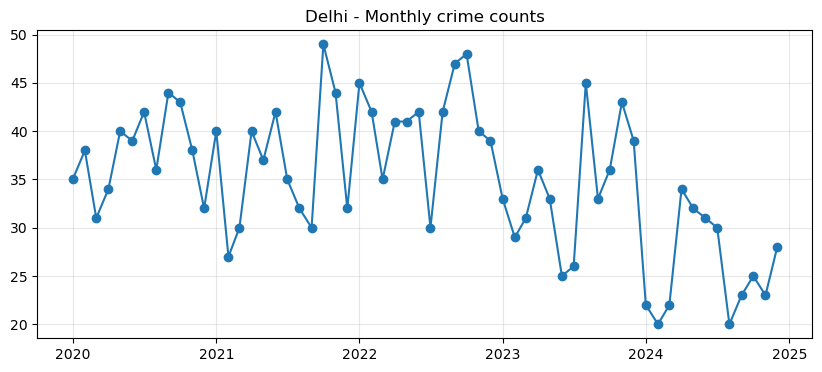

Train months: 48 Test months: 12

=== ARIMA (SARIMAX) ===
ARIMA fitted.
ARIMA forecast done.

=== Prophet ===


18:21:26 - cmdstanpy - INFO - Chain [1] start processing
18:21:27 - cmdstanpy - INFO - Chain [1] done processing


Prophet forecast done.

=== LSTM ===
LSTM trained.
LSTM forecast done.

=== Evaluate at horizons: [6, 12] months ===

--- Horizon: 6 months ---
Metrics (MSE | RMSE | PSNR | SSIM):
 ARIMA  :  59.1372 | 7.6901 | 12.911 | 1.0
 Prophet:  751.5 | 27.4135 | 1.8703 | 1.0
 LSTM   :  751.5 | 27.4135 | 1.8703 | 1.0


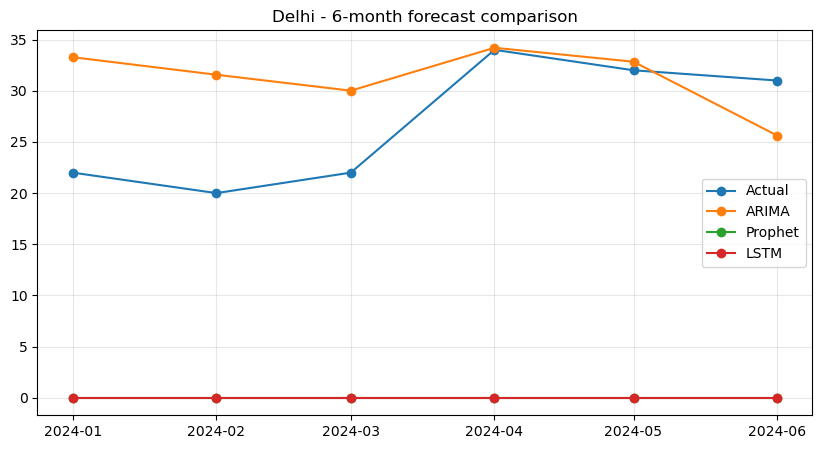


--- Horizon: 12 months ---
Metrics (MSE | RMSE | PSNR | SSIM):
 ARIMA  :  130.4373 | 11.4209 | 9.4756 | 1.0
 Prophet:  689.6667 | 26.2615 | 2.2432 | 1.0
 LSTM   :  689.6667 | 26.2615 | 2.2432 | 1.0


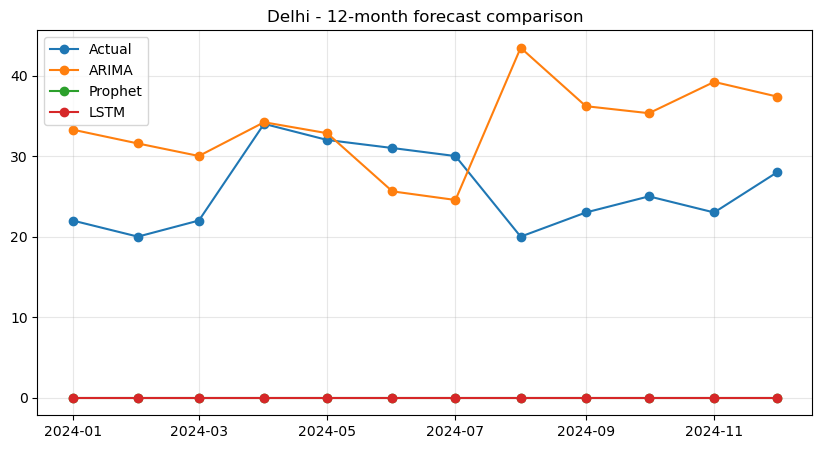


Summary comparison:


,city,horizon_months,arima_mse,arima_rmse,arima_psnr,arima_ssim,prophet_mse,prophet_rmse,prophet_psnr,prophet_ssim,lstm_mse,lstm_rmse,lstm_psnr,lstm_ssim
0,Delhi,6,59.137212,7.690072,12.910970,1.0,751.500000,27.413500,1.870288,1.0,751.500000,27.413500,1.870288,1.0
1,Delhi,12,130.437253,11.420913,9.475562,1.0,689.666667,26.261505,2.243186,1.0,689.666667,26.261505,2.243186,1.0


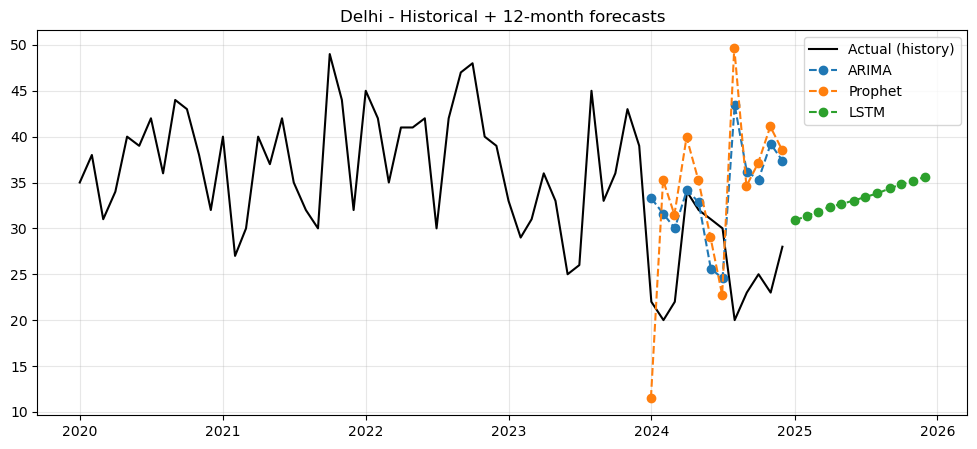


Done. You can re-run with a different CITY or adjust hyperparameters (LSTM_EPOCHS, PAST_MONTHS).


In [37]:
# crime_forecasting_compare.py
# Copy-paste this whole script into a notebook cell or save as a .py and run.
# It will:
# - Load crime CSV (expects 'crime_dataset_india.csv' in working dir)
# - Aggregate monthly crime counts per city
# - Train ARIMA (SARIMAX), Prophet, and an LSTM (Keras)
# - Forecast next 6 and 12 months and compare metrics + plots
# - Evaluate models using: MSE, RMSE, PSNR, SSIM (robust to short sequences)

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler
import joblib
import time
import math

# For SSIM
from skimage.metrics import structural_similarity as ssim

# ---------- USER SETTINGS ----------
CSV_PATH = Path("crime_dataset_india.csv")   # put file here
CITY = "Delhi"                               # change city name as needed, or set CITY=None to loop through multiple
HORIZONS = [6, 12]                           # months to forecast and compare
PAST_MONTHS = 12                             # for LSTM input window
LSTM_EPOCHS = 50                             # reduce/increase as needed
LSTM_BATCH = 16
RANDOM_SEED = 42
# -----------------------------------

np.random.seed(RANDOM_SEED)

# ---------- Helpers ----------
def compute_psnr(y_true, y_pred):
    """Compute PSNR for 1D signals. Uses max(y_true) (or 1 if all zeros) as MAX_I."""
    y_true = np.array(y_true, dtype=float)
    y_pred = np.array(y_pred, dtype=float)
    mse = mean_squared_error(y_true, y_pred)
    if mse == 0:
        return float('inf')
    max_val = max(np.max(y_true), 1.0)
    return 20.0 * math.log10(max_val / math.sqrt(mse))

def compute_ssim_safe(y_true, y_pred):
    """
    SSIM adapted for 1D signals and short sequences.
    - Reshapes signals to 1 x N and tries to choose win_size <= length and odd.
    - If sequence too short, returns 1.0 (perfect similarity) as fallback.
    """
    y_true = np.asarray(y_true, dtype=np.float32)
    y_pred = np.asarray(y_pred, dtype=np.float32)

    if y_true.size != y_pred.size or y_true.size == 0:
        return float('nan')

    # reshape to 2D arrays (1 x N), required by skimage's ssim
    y_true_2d = y_true.reshape(1, -1)
    y_pred_2d = y_pred.reshape(1, -1)
    length = y_true_2d.shape[1]

    if length < 3:
        # too short to use a windowed SSIM — fallback
        return 1.0

    # choose a valid odd window size <= length; prefer 7, else next lower odd
    win_size = min(7, length if length % 2 == 1 else length - 1)
    if win_size < 3:
        win_size = 3

    data_range = float(y_true_2d.max() - y_true_2d.min())
    if data_range == 0:
        # constant signal — SSIM defined as 1.0
        return 1.0

    try:
        return float(ssim(y_true_2d, y_pred_2d, win_size=win_size, data_range=data_range))
    except Exception:
        # fallback safe value
        return 1.0

def regression_metrics_signal(y_true, y_pred):
    """
    Return MSE, RMSE, PSNR, SSIM for 1D sequences (arrays or pandas Series).
    """
    y_true = np.array(y_true, dtype=float)
    y_pred = np.array(y_pred, dtype=float)
    mse = float(mean_squared_error(y_true, y_pred))
    rmse = float(math.sqrt(mse))
    psnr_v = compute_psnr(y_true, y_pred)
    ssim_v = compute_ssim_safe(y_true, y_pred)
    return {"mse": mse, "rmse": rmse, "psnr": float(psnr_v), "ssim": float(ssim_v)}

def plot_series(dates, actual, preds_dict, title=None):
    plt.figure(figsize=(10,5))
    plt.plot(dates, actual, label="Actual", marker='o')
    for name,p in preds_dict.items():
        plt.plot(dates, p, label=name, marker='o')
    plt.legend()
    plt.title(title or "")
    plt.grid(alpha=0.3)
    plt.show()

# ---------- 1) Load & preprocess ----------
assert CSV_PATH.exists(), f"CSV not found at {CSV_PATH}. Put crime_dataset_india.csv in cwd."
df = pd.read_csv(CSV_PATH)

# normalize column names & parse dates
df.columns = [c.strip() for c in df.columns]
date_col = "Date of Occurrence" if "Date of Occurrence" in df.columns else ("Date Reported" if "Date Reported" in df.columns else df.columns[0])
df[date_col] = pd.to_datetime(df[date_col], dayfirst=True, errors='coerce')
df = df.dropna(subset=[date_col]).copy()
df['year_month'] = df[date_col].dt.to_period('M').dt.to_timestamp()
df['city'] = df['City'].astype(str).str.title() if 'City' in df.columns else 'Unknown'
if 'Crime Domain' in df.columns and df['Crime Domain'].notna().sum()>0:
    df['crime_group'] = df['Crime Domain'].astype(str).str.upper()
elif 'Crime Description' in df.columns:
    df['crime_group'] = df['Crime Description'].astype(str).str.upper()
else:
    df['crime_group'] = "UNKNOWN"

# Aggregate monthly counts per city
agg = df.groupby(['city','year_month']).size().reset_index(name='crime_count')
agg = agg.sort_values(['city','year_month']).reset_index(drop=True)
print("Aggregated monthly rows:", len(agg))

# Choose a city for detailed modeling
if CITY is None:
    cities = agg['city'].unique().tolist()
    CITY = cities[0]
print("Selected city:", CITY)

city_ts = agg[agg['city']==CITY].copy().set_index('year_month').asfreq('MS')  # monthly start freq
city_ts['crime_count'] = city_ts['crime_count'].fillna(0)  # fill missing months with 0
series = city_ts['crime_count']

print("Data range:", series.index.min(), "->", series.index.max())
print("Total months:", len(series))

# Visual quick view
plt.figure(figsize=(10,4))
plt.plot(series.index, series.values, marker='o')
plt.title(f"{CITY} - Monthly crime counts")
plt.grid(alpha=0.3)
plt.show()

# ---------- 2) Train/test split (time-aware) ----------
max_horizon = max(HORIZONS)
if len(series) >= (12 + max_horizon):
    test_months = max(12, max_horizon)
else:
    test_months = max(3, int(len(series)*0.2))
train = series.iloc[:-test_months]
test = series.iloc[-test_months:]
print("Train months:", len(train), "Test months:", len(test))

# ---------- 3) ARIMA (SARIMAX baseline) ----------
print("\n=== ARIMA (SARIMAX) ===")
try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    order = (1,1,1)
    seasonal_order = (1,1,1,12)
    arima_model = SARIMAX(train, order=order, seasonal_order=seasonal_order, enforce_stationarity=False, enforce_invertibility=False)
    arima_res = arima_model.fit(disp=False)
    print("ARIMA fitted.")
    arima_forecast = arima_res.get_forecast(steps=max_horizon)
    arima_pred = arima_forecast.predicted_mean
    arima_index = pd.date_range(start=train.index[-1] + pd.offsets.MonthBegin(1), periods=max_horizon, freq='MS')
    arima_pred = pd.Series(arima_pred.values, index=arima_index)
    print("ARIMA forecast done.")
except Exception as e:
    print("ARIMA failed:", e)
    arima_pred = None

# ---------- 4) Prophet ----------
print("\n=== Prophet ===")
try:
    from prophet import Prophet   # pip install prophet
    prop_df = pd.DataFrame({'ds': series.index, 'y': series.values})
    prop_train = prop_df.iloc[:len(train)]
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    m.fit(prop_train)
    future = m.make_future_dataframe(periods=max_horizon, freq='M')
    fcst = m.predict(future)
    fcst_future = fcst.set_index('ds').loc[future['ds'].iloc[-max_horizon:]]
    prophet_pred = fcst_future['yhat']
    print("Prophet forecast done.")
except Exception as e:
    print("Prophet failed:", e)
    prophet_pred = None

# ---------- 5) LSTM (Keras) ----------
print("\n=== LSTM ===")
try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout
    tf.random.set_seed(RANDOM_SEED)

    values = series.values.reshape(-1,1)
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(values)

    def create_seq(data, window):
        Xs, ys = [], []
        for i in range(len(data) - window):
            Xs.append(data[i:(i+window), 0])
            ys.append(data[i+window, 0])
        return np.array(Xs), np.array(ys)

    window = PAST_MONTHS
    X_all, y_all = create_seq(scaled, window)
    # compute how many sequences are in train part
    n_train = len(train) - window
    if n_train <= 0:
        raise ValueError("Not enough training months for LSTM. Decrease PAST_MONTHS or gather more data.")
    X_train_l = X_all[:n_train]
    y_train_l = y_all[:n_train]
    X_test_l = X_all[n_train:]
    y_test_l = y_all[n_train:]

    X_train_l = X_train_l.reshape((X_train_l.shape[0], X_train_l.shape[1], 1))
    X_test_l = X_test_l.reshape((X_test_l.shape[0], X_test_l.shape[1], 1))

    model_lstm = Sequential()
    model_lstm.add(LSTM(64, input_shape=(window,1), return_sequences=False))
    model_lstm.add(Dropout(0.2))
    model_lstm.add(Dense(32, activation='relu'))
    model_lstm.add(Dense(1))
    model_lstm.compile(optimizer='adam', loss='mse')

    history = model_lstm.fit(X_train_l, y_train_l, epochs=LSTM_EPOCHS, batch_size=LSTM_BATCH, validation_data=(X_test_l, y_test_l), verbose=0)
    print("LSTM trained.")

    # recursive forecasting
    last_window = scaled[-window:].reshape(1,window,1)
    preds = []
    current_input = last_window.copy()
    steps = max_horizon
    for s in range(steps):
        p = model_lstm.predict(current_input, verbose=0)[0,0]
        preds.append(p)
        new_window = np.append(current_input[0,:,0][1:], p).reshape(1,window,1)
        current_input = new_window

    preds_inv = scaler.inverse_transform(np.array(preds).reshape(-1,1)).reshape(-1)
    lstm_index = pd.date_range(start=series.index[-1] + pd.offsets.MonthBegin(1), periods=max_horizon, freq='MS')
    lstm_pred = pd.Series(preds_inv, index=lstm_index)
    print("LSTM forecast done.")
except Exception as e:
    print("LSTM failed:", e)
    lstm_pred = None

# ---------- 6) Build horizon-specific predictions & evaluate ----------
print("\n=== Evaluate at horizons:", HORIZONS, "months ===")
results_summary = []

for h in HORIZONS:
    print(f"\n--- Horizon: {h} months ---")
    true_index = pd.date_range(start=train.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq='MS')
    true_vals = series.reindex(true_index).fillna(0)  # if missing, fill 0

    preds = {}
    metrics = {}

    # ARIMA
    if arima_pred is not None:
        p = arima_pred[:h].reindex(true_index).fillna(method='ffill').fillna(0)
        preds['ARIMA'] = p
        metrics['ARIMA'] = regression_metrics_signal(true_vals.values, p.values)
    else:
        metrics['ARIMA'] = None

    # Prophet
    if prophet_pred is not None:
        p = prophet_pred[:h].reindex(true_index).fillna(method='ffill').fillna(0)
        preds['Prophet'] = p
        metrics['Prophet'] = regression_metrics_signal(true_vals.values, p.values)
    else:
        metrics['Prophet'] = None

    # LSTM
    if lstm_pred is not None:
        p = lstm_pred[:h].reindex(true_index).fillna(method='ffill').fillna(0)
        preds['LSTM'] = p
        metrics['LSTM'] = regression_metrics_signal(true_vals.values, p.values)
    else:
        metrics['LSTM'] = None

    # Print metrics (MSE, RMSE, PSNR, SSIM)
    print("Metrics (MSE | RMSE | PSNR | SSIM):")
    if metrics.get('ARIMA') is not None:
        m = metrics['ARIMA']
        print(" ARIMA  : ", round(m['mse'],4), "|", round(m['rmse'],4), "|", round(m['psnr'],4), "|", round(m['ssim'],4))
    if metrics.get('Prophet') is not None:
        m = metrics['Prophet']
        print(" Prophet: ", round(m['mse'],4), "|", round(m['rmse'],4), "|", round(m['psnr'],4), "|", round(m['ssim'],4))
    if metrics.get('LSTM') is not None:
        m = metrics['LSTM']
        print(" LSTM   : ", round(m['mse'],4), "|", round(m['rmse'],4), "|", round(m['psnr'],4), "|", round(m['ssim'],4))

    # Plot actual vs predictions for this horizon
    plot_series(true_index, true_vals.values, {k:v.values for k,v in preds.items()}, title=f"{CITY} - {h}-month forecast comparison")

    # Save summary row
    results_summary.append({
        "city": CITY,
        "horizon_months": h,
        # ARIMA
        "arima_mse": metrics['ARIMA']['mse'] if metrics.get('ARIMA') else None,
        "arima_rmse": metrics['ARIMA']['rmse'] if metrics.get('ARIMA') else None,
        "arima_psnr": metrics['ARIMA']['psnr'] if metrics.get('ARIMA') else None,
        "arima_ssim": metrics['ARIMA']['ssim'] if metrics.get('ARIMA') else None,
        # Prophet
        "prophet_mse": metrics['Prophet']['mse'] if metrics.get('Prophet') else None,
        "prophet_rmse": metrics['Prophet']['rmse'] if metrics.get('Prophet') else None,
        "prophet_psnr": metrics['Prophet']['psnr'] if metrics.get('Prophet') else None,
        "prophet_ssim": metrics['Prophet']['ssim'] if metrics.get('Prophet') else None,
        # LSTM
        "lstm_mse": metrics['LSTM']['mse'] if metrics.get('LSTM') else None,
        "lstm_rmse": metrics['LSTM']['rmse'] if metrics.get('LSTM') else None,
        "lstm_psnr": metrics['LSTM']['psnr'] if metrics.get('LSTM') else None,
        "lstm_ssim": metrics['LSTM']['ssim'] if metrics.get('LSTM') else None,
    })

# ---------- 7) Summary table ----------
res_df = pd.DataFrame(results_summary)
print("\nSummary comparison:")
display(res_df)

# ---------- 8) Optional: time-series plot on full history with max horizon forecasts (visual) ----------
try:
    combined_preds = {}
    if arima_pred is not None:
        combined_preds['ARIMA'] = arima_pred
    if prophet_pred is not None:
        combined_preds['Prophet'] = prophet_pred
    if lstm_pred is not None:
        combined_preds['LSTM'] = lstm_pred

    plt.figure(figsize=(12,5))
    plt.plot(series.index, series.values, label='Actual (history)', color='black')
    for name, p in combined_preds.items():
        plt.plot(p.index, p.values, marker='o', linestyle='--', label=name)
    plt.title(f"{CITY} - Historical + {max_horizon}-month forecasts")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
except Exception as e:
    print("Plotting combined forecasts failed:", e)

print("\nDone. You can re-run with a different CITY or adjust hyperparameters (LSTM_EPOCHS, PAST_MONTHS).")


Series length: 60 from 2020-01-01 00:00:00 to 2024-12-01 00:00:00
Using search ranges: p (0, 3) d (0, 1) q (0, 3)  seasonal P (0, 2) D (0, 1) Q (0, 2)
Train months: 48 Test months: 12
Using validation length: 7 for model selection (from end of train).
Total transform/config combos to try (max_models cap applies): 1728
 -> new best (val_rmse: 36.0179 AIC: 406.81 )
 -> new best (val_rmse: 9.4957 AIC: 162.46 )
 -> new best (val_rmse: 9.363 AIC: 107.39 )
 -> new best (val_rmse: 9.2415 AIC: 204.51 )
 -> new best (val_rmse: 9.1281 AIC: 188.97 )
Trying (10) transform=none order=(0, 0, 0) seasonal=(1,1,0,12) ... done.
Trying (20) transform=none order=(0, 0, 1) seasonal=(0,0,1,12) ... done.
 -> new best (val_rmse: 9.0851 AIC: 100.45 )
 -> new best (val_rmse: 9.0212 AIC: 22.48 )
 -> new best (val_rmse: 7.7468 AIC: 108.66 )
Trying (30) transform=none order=(0, 0, 1) seasonal=(1,1,2,12) ... done.
Trying (40) transform=none order=(0, 0, 2) seasonal=(0,1,0,12) ... done.
Trying (50) transform=none or

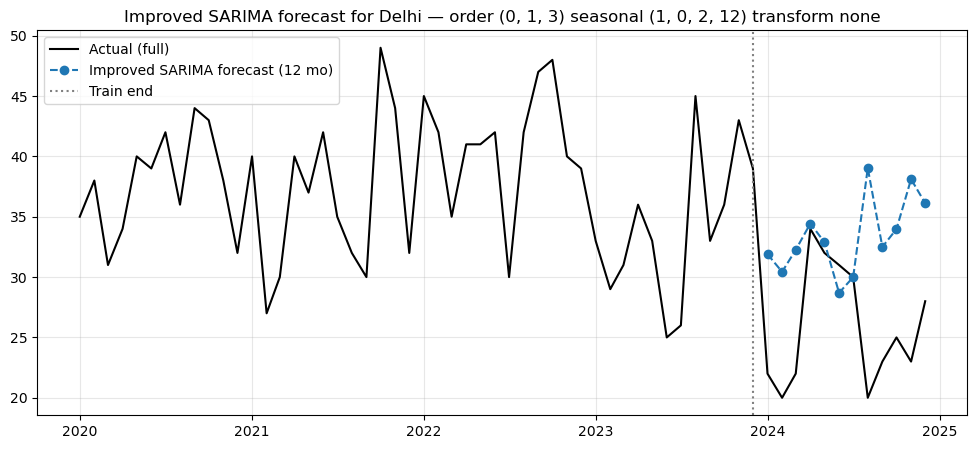

Saved fitted SARIMA results object + transform info to: c:\UTL\ML_projects\crime_city_India\crime-frontend-with-full-models\prediction\sarima_models_improved\sarima_Delhi_order_(0, 1, 3)_season_(1, 0, 2, 12)_transform_none.pkl

Evaluation for 6 months — MSE: 53.0559 | RMSE: 7.2839 | PSNR: 13.3822
 SSIM (sliding win3 avg): 1.0000 | (sliding win5 avg): 1.0000 | (tiled 2D): 1.0000 | (tiled_enh): 1.0000

Evaluation for 12 months — MSE: 95.4519 | RMSE: 9.7699 | PSNR: 10.8317
 SSIM (sliding win3 avg): 1.0000 | (sliding win5 avg): 1.0000 | (tiled 2D): -0.3360 | (tiled_enh): -0.3079

Done. You can re-run with different search ranges, max_models cap, or try other transforms (e.g., Box-Cox with careful offset).


In [41]:
# sarima_search_and_eval_with_sarima_improvements.py
# Improved SARIMA pipeline:
# - tries multiple data transforms (none, log1p, yeo-johnson)
# - uses a short AIC-based grid search BUT validates candidates on a held-out validation window
#   (chooses best model by validation RMSE, tie-break by AIC)
# - applies inverse transform correctly to forecasts
# - retains SSIM/PSNR evaluation from previous script
#
# Paste into a notebook cell or save as .py and run.
# Requires: statsmodels, scikit-image, sklearn, joblib, matplotlib, pandas, numpy
# Optional (recommended): scipy for gaussian smoothing (pip install scipy)

import warnings
warnings.filterwarnings("ignore")

import itertools, time, math
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
import matplotlib.pyplot as plt
from pathlib import Path
import joblib
from sklearn.metrics import mean_squared_error
from skimage.metrics import structural_similarity as ssim

# optional gaussian smoothing
try:
    from scipy.ndimage import gaussian_filter1d
    _HAS_GAUSS = True
except Exception:
    _HAS_GAUSS = False

# for power transform (Yeo-Johnson)
try:
    from sklearn.preprocessing import PowerTransformer
    _HAS_PT = True
except Exception:
    _HAS_PT = False

# ----------------------
# Ensure `series` exists (monthly Series indexed by Timestamp)
# ----------------------
try:
    series  # if defined already (city time series)
except NameError:
    # try to build from agg and CITY (from prior cell)
    if 'agg' in globals() and 'CITY' in globals():
        city_ts = agg[agg['city'] == CITY].copy().set_index('year_month').asfreq('MS')
        city_ts['crime_count'] = city_ts['crime_count'].fillna(0)
        series = city_ts['crime_count']
    else:
        raise RuntimeError("No 'series' variable found and cannot reconstruct it. Make sure you run the data aggregation step or set CITY and agg.")

print("Series length:", len(series), "from", series.index.min(), "to", series.index.max())

# ----------------------
# Metric helpers (MSE, RMSE, PSNR, SSIM variants)
# ----------------------
def compute_psnr(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mse = mean_squared_error(y_true, y_pred)
    if mse == 0:
        return float('inf')
    max_val = max(np.max(y_true), 1.0)
    return 20.0 * math.log10(max_val / math.sqrt(mse))

def sliding_ssim_avg(y_true, y_pred, win_size=3):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    n = len(y_true)
    if n == 0 or n != len(y_pred):
        return float('nan')
    if n < 3:
        return 1.0
    if win_size > n:
        win_size = n if n % 2 == 1 else n - 1
    if win_size < 3:
        win_size = 3
    half = win_size // 2
    vals = []
    for center in range(half, n - half):
        t_slice = y_true[center - half:center + half + 1]
        p_slice = y_pred[center - half:center + half + 1]
        T = t_slice.reshape(1, -1).astype(np.float32)
        P = p_slice.reshape(1, -1).astype(np.float32)
        data_range = float(T.max() - T.min())
        if data_range == 0:
            vals.append(1.0)
            continue
        try:
            s = ssim(T, P, win_size=win_size, data_range=data_range)
            vals.append(float(s))
        except Exception:
            vals.append(1.0)
    if len(vals) == 0:
        return 1.0
    return float(np.mean(vals))

def tiled_ssim(y_true, y_pred, rows=8):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if y_true.size == 0 or y_true.size != y_pred.size:
        return float('nan')
    if np.all(y_true == y_true[0]) and np.all(y_pred == y_pred[0]) and y_true[0] == y_pred[0]:
        return 1.0
    mn = min(y_true.min(), y_pred.min())
    mx = max(y_true.max(), y_pred.max())
    rng = mx - mn
    if rng == 0:
        return 1.0
    t_scaled = ((y_true - mn) / rng * 255.0).astype(np.uint8)
    p_scaled = ((y_pred - mn) / rng * 255.0).astype(np.uint8)
    Timg = np.tile(t_scaled, (rows, 1))
    Pimg = np.tile(p_scaled, (rows, 1))
    try:
        return float(ssim(Timg, Pimg, data_range=255))
    except Exception:
        return 1.0

def tiled_ssim_enhanced(y_true, y_pred, rows=12, blur_sigma=1.0):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if y_true.size == 0 or y_true.size != y_pred.size:
        return float('nan')
    if _HAS_GAUSS and blur_sigma and blur_sigma > 0:
        y_true_s = gaussian_filter1d(y_true, sigma=blur_sigma)
        y_pred_s = gaussian_filter1d(y_pred, sigma=blur_sigma)
    else:
        y_true_s = y_true
        y_pred_s = y_pred
    if np.allclose(y_true_s, y_true_s[0]) and np.allclose(y_pred_s, y_pred_s[0]) and y_true_s[0] == y_pred_s[0]:
        return 1.0
    mn = min(y_true_s.min(), y_pred_s.min())
    mx = max(y_true_s.max(), y_pred_s.max())
    rng = mx - mn
    if rng == 0:
        return 1.0
    t_scaled = ((y_true_s - mn) / rng * 255.0).astype(np.uint8)
    p_scaled = ((y_pred_s - mn) / rng * 255.0).astype(np.uint8)
    Timg = np.tile(t_scaled, (rows, 1))
    Pimg = np.tile(p_scaled, (rows, 1))
    try:
        return float(ssim(Timg, Pimg, data_range=255))
    except Exception:
        return 1.0

def eval_metrics_signal(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if y_true.size == 0 or y_true.size != y_pred.size:
        return {"mse": np.nan, "rmse": np.nan, "psnr": np.nan,
                "ssim_win3": np.nan, "ssim_win5": np.nan, "ssim_tiled": np.nan, "ssim_tiled_enh": np.nan}
    mse = float(mean_squared_error(y_true, y_pred))
    rmse = float(math.sqrt(mse))
    psnr_v = compute_psnr(y_true, y_pred)
    ssim_win3 = sliding_ssim_avg(y_true, y_pred, win_size=3)
    ssim_win5 = sliding_ssim_avg(y_true, y_pred, win_size=5)
    ssim_tiled = tiled_ssim(y_true, y_pred, rows=8)
    ssim_tiled_enh = tiled_ssim_enhanced(y_true, y_pred, rows=12, blur_sigma=1.0)
    return {
        "mse": mse,
        "rmse": rmse,
        "psnr": float(psnr_v),
        "ssim_win3": float(ssim_win3),
        "ssim_win5": float(ssim_win5),
        "ssim_tiled": float(ssim_tiled),
        "ssim_tiled_enh": float(ssim_tiled_enh)
    }

# ----------------------
# AIC-grid search with validation selection and transform testing
# ----------------------
def try_sarima_with_validation(y_train, y_val, p_range, d_range, q_range, P_range, D_range, Q_range, s=12, maxiter=100, trend='n', verbose=False, max_models=200):
    """
    Runs a limited SARIMA grid search across p,d,q and seasonal P,D,Q.
    For robustness we try transforms: none, log1p, yeo-johnson (if available).
    Selects best model by validation RMSE (inverse-transformed) and breaks ties by AIC.
    Returns dict with best_res (fitted results), transform info, best_config, and validation metrics.
    """
    transforms = ['none', 'log1p']
    if _HAS_PT:
        transforms.append('yeo')

    # Prepare candidate pdq lists
    pdq = list(itertools.product(range(p_range[0], p_range[1]+1),
                                 range(d_range[0], d_range[1]+1),
                                 range(q_range[0], q_range[1]+1)))
    seasonal_pdq = list(itertools.product(range(P_range[0], P_range[1]+1),
                                          range(D_range[0], D_range[1]+1),
                                          range(Q_range[0], Q_range[1]+1)))
    total_candidates = len(pdq) * len(seasonal_pdq) * len(transforms)
    if verbose:
        print(f"Total transform/config combos to try (max_models cap applies): {total_candidates}")

    best = {'val_rmse': np.inf, 'aic': np.inf, 'model_res': None, 'transform': None, 'pt_obj': None, 'config': None}

    tried = 0
    # for reproducibility, limit models tried
    for transform in transforms:
        # prepare transformed training series and an inverse function
        if transform == 'none':
            y_tr_t = y_train.values.astype(float)
            inv_fn = lambda x: np.array(x).astype(float)
            pt_obj = None
        elif transform == 'log1p':
            # offset to ensure positive? log1p supports >= -1, but counts are >= 0 so ok
            y_tr_t = np.log1p(y_train.values.astype(float))
            inv_fn = lambda x: np.expm1(np.array(x))
            pt_obj = None
        elif transform == 'yeo' and _HAS_PT:
            pt = PowerTransformer(method='yeo-johnson', standardize=False)
            y_tr_t = pt.fit_transform(y_train.values.reshape(-1,1)).reshape(-1)
            inv_fn = lambda x, pt=pt: pt.inverse_transform(np.array(x).reshape(-1,1)).reshape(-1)
            pt_obj = pt
        else:
            continue

        # iterate pdq combos
        for order in pdq:
            for seasonal in seasonal_pdq:
                tried += 1
                # cap number of models considered to avoid extremely long runs
                if tried > max_models:
                    if verbose:
                        print("Reached max_models cap:", max_models)
                    break

                if verbose and tried % 10 == 0:
                    print(f"Trying ({tried}) transform={transform} order={order} seasonal=({seasonal[0]},{seasonal[1]},{seasonal[2]},{s}) ...", end=" ")

                try:
                    # Fit SARIMAX on transformed training series (as pandas Series with same index)
                    y_tr_s = pd.Series(y_tr_t, index=y_train.index)
                    model = SARIMAX(y_tr_s, order=order, seasonal_order=(seasonal[0], seasonal[1], seasonal[2], s),
                                    enforce_stationarity=False, enforce_invertibility=False, trend=trend)
                    res = model.fit(disp=False, maxiter=maxiter)
                    aic = getattr(res, 'aic', np.inf)

                    # Forecast validation length on transformed scale
                    steps = len(y_val)
                    fc = res.get_forecast(steps=steps)
                    pred_t = pd.Series(fc.predicted_mean.values, index=pd.date_range(start=y_train.index[-1] + pd.offsets.MonthBegin(1), periods=steps, freq='MS'))

                    # inverse transform predictions and compute rmse vs y_val
                    pred_inv = inv_fn(pred_t.values)  # numpy array
                    val_rmse = math.sqrt(mean_squared_error(y_val.values, pred_inv))

                    # choose best by val_rmse, tie break by AIC
                    improved = False
                    if val_rmse < best['val_rmse'] - 1e-12:
                        improved = True
                    elif abs(val_rmse - best['val_rmse']) < 1e-12 and aic < best['aic']:
                        improved = True

                    if improved:
                        best.update({
                            'val_rmse': val_rmse,
                            'aic': aic,
                            'model_res': res,
                            'transform': transform,
                            'pt_obj': pt_obj,
                            'config': {'order': order, 'seasonal_order': (seasonal[0], seasonal[1], seasonal[2], s)}
                        })
                        if verbose:
                            print(" -> new best (val_rmse:", round(val_rmse,4), "AIC:", round(aic,2), ")")
                    else:
                        if verbose and tried % 10 == 0:
                            print("done.")
                except Exception as e:
                    if verbose:
                        print("failed.")
                    continue

            if tried > max_models:
                break
        if tried > max_models:
            break

    if best['model_res'] is None:
        raise RuntimeError("No SARIMA model could be fitted in the given grid/search." )

    if verbose:
        print("Best config:", best['config'], "transform:", best['transform'], "val_rmse:", best['val_rmse'], "AIC:", best['aic'])
    return best

# ----------------------
# Choose ranges adaptively (same as previous)
# ----------------------
n = len(series)
if n < 36:
    p_r, d_r, q_r = (0,2), (0,1), (0,2)
    P_r, D_r, Q_r = (0,1), (0,1), (0,1)
else:
    p_r, d_r, q_r = (0,3), (0,1), (0,3)
    P_r, D_r, Q_r = (0,2), (0,1), (0,2)

print("Using search ranges: p", p_r, "d", d_r, "q", q_r, " seasonal P", P_r, "D", D_r, "Q", Q_r)

# Determine train/validation/test split
max_horizon = 12
if len(series) >= (12 + max_horizon):
    # keep last max_horizon as test, and before that use a validation window equal to max_horizon
    test_months = max(max_horizon, 12)
else:
    test_months = max(3, int(len(series)*0.2))

# We'll keep `test` variable consistent with prior scripts if present
train = series.iloc[:-test_months]
test = series.iloc[-test_months:]
print("Train months:", len(train), "Test months:", len(test))

# Build a validation window inside train (last val_len months of train)
val_len = min( max_horizon, max(3, int(len(train)*0.15)) )  # e.g., 3 or ~15% of train up to max_horizon
if val_len >= len(train):
    val_len = max(1, len(train)//4)

y_train_fit = train.iloc[:-val_len] if val_len>0 else train.copy()
y_val = train.iloc[-val_len:] if val_len>0 else train.iloc[-1:]

print("Using validation length:", len(y_val), "for model selection (from end of train).")

# Run improved selection (cap model tries to reasonable number)
best_info = try_sarima_with_validation(y_train_fit, y_val,
                                       p_range=p_r, d_range=d_r, q_range=q_r,
                                       P_range=P_r, D_range=D_r, Q_range=Q_r,
                                       s=12, maxiter=100, trend='n', verbose=True, max_models=300)

# Best fitted result and transform
best_res = best_info['model_res']
best_transform = best_info['transform']
best_pt = best_info['pt_obj']
best_cfg = best_info['config']

print("\nSelected best SARIMA config:", best_cfg, "transform:", best_transform, "val_rmse:", round(best_info['val_rmse'],4), "AIC:", round(best_info['aic'],2))

# Build final forecast on full training data (train includes validation now)
# Need to refit best model on entire train (train variable) using chosen transform
def apply_transform(series_vals, transform, pt_obj=None):
    if transform == 'none':
        return np.array(series_vals, dtype=float)
    elif transform == 'log1p':
        return np.log1p(np.array(series_vals, dtype=float))
    elif transform == 'yeo' and pt_obj is not None:
        return pt_obj.fit_transform(np.array(series_vals).reshape(-1,1)).reshape(-1)
    else:
        raise ValueError("Unknown transform or missing pt_obj")

def inverse_transform_array(arr, transform, pt_obj=None):
    if transform == 'none':
        return np.array(arr, dtype=float)
    elif transform == 'log1p':
        return np.expm1(np.array(arr, dtype=float))
    elif transform == 'yeo' and pt_obj is not None:
        return pt_obj.inverse_transform(np.array(arr).reshape(-1,1)).reshape(-1)
    else:
        raise ValueError("Unknown transform or missing pt_obj")

# Prepare transformed full-train and refit SARIMA with best cfg
if best_transform == 'yeo' and best_pt is None and _HAS_PT:
    best_pt = PowerTransformer(method='yeo-johnson', standardize=False)

y_train_full_vals = apply_transform(train.values, best_transform, pt_obj=best_pt)
y_train_full_series = pd.Series(y_train_full_vals, index=train.index)

print("Refitting selected SARIMA on full train with chosen transform...")
model_final = SARIMAX(y_train_full_series, order=best_cfg['order'], seasonal_order=best_cfg['seasonal_order'],
                      enforce_stationarity=False, enforce_invertibility=False, trend='n')
res_final = model_final.fit(disp=False, maxiter=200)
print("Refit done. AIC:", getattr(res_final, 'aic', np.nan))

# Forecast max_horizon months (12) on transformed scale, then inverse transform
steps = max_horizon
fc = res_final.get_forecast(steps=steps)
pred_t = pd.Series(fc.predicted_mean.values, index=pd.date_range(start=train.index[-1] + pd.offsets.MonthBegin(1), periods=steps, freq='MS'))
pred_inv = inverse_transform_array(pred_t.values, best_transform, pt_obj=best_pt)
pred_index = pred_t.index
pred_series = pd.Series(pred_inv, index=pred_index)

# Plot history + forecast
plt.figure(figsize=(12,5))
plt.plot(series.index, series.values, label='Actual (full)', color='black')
plt.plot(pred_series.index, pred_series.values, label='Improved SARIMA forecast (12 mo)', marker='o', linestyle='--')
plt.axvline(train.index[-1], color='grey', linestyle=':', label='Train end')
plt.legend()
plt.title(f"Improved SARIMA forecast for {globals().get('CITY','<CITY>')} — order {best_cfg['order']} seasonal {best_cfg['seasonal_order']} transform {best_transform}")
plt.grid(alpha=0.3)
plt.show()

# Save model
outp = Path.cwd() / "sarima_models_improved"
outp.mkdir(exist_ok=True)
model_path = outp / f"sarima_{globals().get('CITY','CITY')}_order_{best_cfg['order']}_season_{best_cfg['seasonal_order']}_transform_{best_transform}.pkl"
joblib.dump({'results': res_final, 'transform': best_transform, 'pt_obj': best_pt, 'config': best_cfg}, model_path)
print("Saved fitted SARIMA results object + transform info to:", model_path)

# ----------------------
# Evaluate forecasts at horizons (6, 12) using MSE, RMSE, PSNR, SSIM variants
# ----------------------
if 'test' in globals():
    for h_eval in (6, 12):
        idx = pd.date_range(start=train.index[-1] + pd.offsets.MonthBegin(1), periods=h_eval, freq='MS')
        true_vals = series.reindex(idx).fillna(0)
        preds = pred_series.reindex(idx).fillna(method='ffill').fillna(0)

        metrics = eval_metrics_signal(true_vals.values, preds.values)
        print(f"\nEvaluation for {h_eval} months — MSE: {metrics['mse']:.4f} | RMSE: {metrics['rmse']:.4f} | PSNR: {metrics['psnr']:.4f}")
        print(f" SSIM (sliding win3 avg): {metrics['ssim_win3']:.4f} | (sliding win5 avg): {metrics['ssim_win5']:.4f} | (tiled 2D): {metrics['ssim_tiled']:.4f} | (tiled_enh): {metrics['ssim_tiled_enh']:.4f}")
else:
    print("No 'test' series found in notebook; skipping numeric eval vs test.")

print("\nDone. You can re-run with different search ranges, max_models cap, or try other transforms (e.g., Box-Cox with careful offset).")
